This script creates RSMs for older and younger children within modalities and correlates them. The RSMs are created by calculating the softmax of a child's description to all their other descriptions and their drawing to all their other drawings to see if the representaitonal geometry is similar across modalities. Finally it creates a scatter plot visualization of the cross-modal pairs.

In [1]:
library(dplyr)
library(tidyr)
library(purrr)
library(ggplot2)
library(tidyverse)
library(patchwork)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.4     ✔ tibble    3.3.0
✔ readr     2.1.6     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
drawing_df <- read_csv("../data/tidy/drawings.csv") %>%
  filter(draw_exists == 1, draw_interference == 0)

transcript_df <- read_csv("../data/tidy/utterances.csv") %>%
  filter(utterance_exists == 1, utterance_interference == 0)

Rows: 638 Columns: 31
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): participant_id, target_category, bounding_box, draw_full_features,...
dbl (24): age_months, age_yrs, draw_exists, draw_interference, trial_duratio...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 638 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): participant_id, target_category, utterance_ns, utterance_masked, u...
dbl (18): age_months, age_yrs, utterance_exists, utterance_interference, utt...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
drawing_df %>% names()

[1] "participant_id"            "target_category"          
 [3] "age_months"                "age_yrs"                  
 [5] "is_adult"                  "is_child"                 
 [7] "draw_exists"               "draw_interference"        
 [9] "trial_duration"            "num_strokes"              
[11] "draw_duration"             "mean_intensity"           
[13] "bounding_box"              "draw_cossim_adults"       
[15] "draw_half_cossim_adults"   "n_strokes_found"          
[17] "half_k"                    "draw_cossim_crab"         
[19] "draw_cossim_octopus"       "draw_cossim_seahorse"     
[21] "draw_cossim_shark"         "draw_cossim_turtle"       
[23] "draw_cossim_whale"         "draw_probability_crab"    
[25] "draw_probability_octopus"  "draw_probability_seahorse"
[27] "draw_probability_shark"    "draw_probability_turtle"  
[29] "draw_probability_whale"    "draw_full_features"       
[31] "draw_half_features"

In [4]:
# Summaries

library(stringr)

# --- Save full counts BEFORE filtering (includes adults)
total_drawings_all <- nrow(read_csv("../data/tidy/drawings.csv"))
total_utterances_all <- nrow(read_csv("../data/tidy/utterances.csv"))

# --- Filter to children only (drawing_df / transcript_df already have exists + interference filters) ---
drawing_children <- drawing_df %>%
  filter(is_child, !is.na(age_months))

transcript_children <- transcript_df %>%
  filter(is_child, !is.na(age_months))

# --- Participant-level age summary (children only) ---
child_ages <- bind_rows(
  drawing_children %>% select(participant_id, age_months),
  transcript_children %>% select(participant_id, age_months)
) %>%
  distinct(participant_id, .keep_all = TRUE) %>%
  mutate(age_months = as.numeric(age_months)) %>%
  filter(!is.na(age_months))

mean_age_months <- mean(child_ages$age_months)
sd_age_months   <- sd(child_ages$age_months)
mean_age_years  <- mean_age_months / 12
sd_age_years    <- sd_age_months / 12

total_n <- nrow(child_ages)

# Counts
total_drawings <- nrow(drawing_children)

drawings_by_category <- drawing_children %>%
  count(target_category, name = "n_drawings") %>%
  arrange(target_category)

total_utterances <- nrow(transcript_children)

utterances_by_category <- transcript_children %>%
  count(target_category, name = "n_utterances") %>%
  arrange(target_category)

drawing_participants <- drawing_children %>%
  distinct(participant_id) %>%
  nrow()

utterance_participants <- transcript_children %>%
  distinct(participant_id) %>%
  nrow()

participants_with_both <- inner_join(
  drawing_children %>% distinct(participant_id, target_category),
  transcript_children %>% distinct(participant_id, target_category),
  by = c("participant_id", "target_category")
) %>%
  distinct(participant_id) %>%
  nrow()

total_children_included <- bind_rows(
  drawing_children %>% select(participant_id),
  transcript_children %>% select(participant_id)
) %>%
  distinct() %>%
  nrow()

# Output file
output_path <- "../data_intermediates/summaries/trial_summaries.txt"
dir.create(dirname(output_path), recursive = TRUE, showWarnings = FALSE)

lines <- c(
  "=== CHILDREN'S DATA SUMMARY AFTER EXCLUSIONS ===",
  "",
  "Exclusion criteria applied:",
  "  - Children only (is_child == TRUE; participant_id starts with BD025+)",
  "  - Artifact must exist (draw_exists == 1; utterance_exists == 1)",
  "  - No interference (draw_interference == 0; utterance_interference == 0)",
  "  - Age must be present (no missing age_months)",
  "",
  "Excluded participants (not in analysis):",
  "  - BD049, BD050, BD052, BD064, BD081: no data in features spine",
  "  - BD085, BD097: missing age data (data collection error)",
  "  - BD059, BD067, BD082, BD101: zero valid trials in either modality after exclusions",
  "  - BD119-BD124: INCLUDED (valid participants collected later)",
  "",
  paste0("Total child participants included in analyses: ", total_n),
  "",
  paste0("Mean age (years): ", round(mean_age_years, 2), " (SD = ", round(sd_age_years, 2), ")"),
  paste0("Mean age (months): ", round(mean_age_months, 1), " (SD = ", round(sd_age_months, 1), ")"),
  "",
  "=== DRAWINGS (draw_exists == 1, draw_interference == 0) ===",
  "",
  paste0("Total child drawing trials: ", total_drawings),
  "",
  "Child drawings by category:",
  paste0("  ", drawings_by_category$target_category, ": ", drawings_by_category$n_drawings),
  "",
  paste0("Child participants contributing drawings: ", drawing_participants),
  "",
  "=== UTTERANCES (utterance_exists == 1, utterance_interference == 0) ===",
  "",
  paste0("Total child utterance trials: ", total_utterances),
  "",
  "Child utterances by category:",
  paste0("  ", utterances_by_category$target_category, ": ", utterances_by_category$n_utterances),
  "",
  paste0("Child participants contributing utterances: ", utterance_participants),
  "",
  "=== OVERLAP ===",
  "",
  paste0("Participants with valid drawing AND utterance: ", participants_with_both),
  paste0("Participants with drawing only: ", drawing_participants - participants_with_both),
  paste0("Participants with utterance only: ", utterance_participants - participants_with_both),
  paste0("Total (drawing OR utterance): ", total_children_included),
  "",
  "=== FULL DATASET (all participants, before exclusions) ===",
  "",
  paste0("Total rows in drawings.csv: ", total_drawings_all),
  paste0("Total rows in utterances.csv: ", total_utterances_all)
)

writeLines(lines, output_path)
cat("Summary written to:", output_path, "\n")

Rows: 638 Columns: 31
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): participant_id, target_category, bounding_box, draw_full_features,...
dbl (24): age_months, age_yrs, draw_exists, draw_interference, trial_duratio...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 638 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): participant_id, target_category, utterance_ns, utterance_masked, u...
dbl (18): age_months, age_yrs, utterance_exists, utterance_interference, utt...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Summary written to: ../data_intermediates/summaries/trial_summaries.txt 


In [5]:
categories <- c("crab", "octopus", "seahorse", "shark", "turtle", "whale")

draw_prob_cols <- paste0("draw_probability_", categories)
utt_prob_cols  <- paste0("utterance_probability_", categories)

In [6]:
#Make one child level probability RDM for each participant 
make_probability_rdm <- function(df, pid, prob_cols, categories,
                                 participant_col = "participant_id",
                                 category_col = "target_category") {
  
  sub <- df %>%
    filter(.data[[participant_col]] == pid) %>%
    mutate(
      category_clean = tolower(trimws(.data[[category_col]]))
    )
  
  rdm <- matrix(
    NA_real_,
    nrow = length(categories),
    ncol = length(categories),
    dimnames = list(categories, categories)
  )
  
  for (cat in categories) {
    cat_rows <- sub %>% filter(category_clean == cat)
    
    if (nrow(cat_rows) > 0) {
      rdm[cat, ] <- cat_rows %>%
        summarise(across(all_of(prob_cols), ~ mean(.x, na.rm = TRUE))) %>%
        as.numeric()
    }
  }
  
  rdm
}

In [7]:
#Average RDMs while ignoring missing drawings/descriptions
average_rdms <- function(rdm_list) {
  arr <- simplify2array(rdm_list)
  apply(arr, c(1, 2), function(x) mean(x, na.rm = TRUE))
}

In [8]:
# Median age split — children only
age_df <- bind_rows(
  drawing_df %>% filter(is_child) %>% select(participant_id, age_months),
  transcript_df %>% filter(is_child) %>% select(participant_id, age_months)
) %>%
  filter(!is.na(age_months), age_months < 200) %>%
  distinct(participant_id, .keep_all = TRUE)

median_age <- median(age_df$age_months, na.rm = TRUE)

younger_ids <- age_df %>%
  filter(age_months <= median_age) %>%
  pull(participant_id)

older_ids <- age_df %>%
  filter(age_months > median_age) %>%
  pull(participant_id)

median_age
length(younger_ids)
length(older_ids)

[1] 78

[1] 45

[1] 44

In [9]:
#Build child level RDMs 
draw_rdms <- setNames(
  map(age_df$participant_id, ~ make_probability_rdm(
    drawing_df,
    pid = .x,
    prob_cols = draw_prob_cols,
    categories = categories
  )),
  age_df$participant_id
)

utt_rdms <- setNames(
  map(age_df$participant_id, ~ make_probability_rdm(
    transcript_df,
    pid = .x,
    prob_cols = utt_prob_cols,
    categories = categories
  )),
  age_df$participant_id
)

In [10]:
#Average RDMs by age group and modality
younger_draw_rdm <- average_rdms(draw_rdms[younger_ids])
younger_utt_rdm  <- average_rdms(utt_rdms[younger_ids])

older_draw_rdm <- average_rdms(draw_rdms[older_ids])
older_utt_rdm  <- average_rdms(utt_rdms[older_ids])

In [11]:
#Correlate lower triangles
lower_tri_vec <- function(mat) {
  mat[lower.tri(mat)]
}

younger_cor <- cor(
  lower_tri_vec(younger_draw_rdm),
  lower_tri_vec(younger_utt_rdm),
  use = "pairwise.complete.obs",
  method = "spearman"
)

older_cor <- cor(
  lower_tri_vec(older_draw_rdm),
  lower_tri_vec(older_utt_rdm),
  use = "pairwise.complete.obs",
  method = "spearman"
)

younger_cor
older_cor

[1] 0.5642857

[1] 0.9

In [12]:
#Plot four RDMs
rdm_to_long <- function(mat, age_group, modality) {
  as.data.frame(as.table(mat)) %>%
    rename(
      row_category = Var1,
      col_category = Var2,
      value = Freq
    ) %>%
    mutate(
      age_group = age_group,
      modality = modality,
      row_category = factor(row_category, levels = rev(categories)),
      col_category = factor(col_category, levels = categories),
      age_group = factor(age_group, levels = c("Younger children", "Older children")),
      modality = factor(modality, levels = c("Drawings", "Utterances"))
    )
}

rdm_plot_df <- bind_rows(
  rdm_to_long(younger_draw_rdm, "Younger children", "Drawings"),
  rdm_to_long(younger_utt_rdm,  "Younger children", "Utterances"),
  rdm_to_long(older_draw_rdm,   "Older children", "Drawings"),
  rdm_to_long(older_utt_rdm,    "Older children", "Utterances")
)

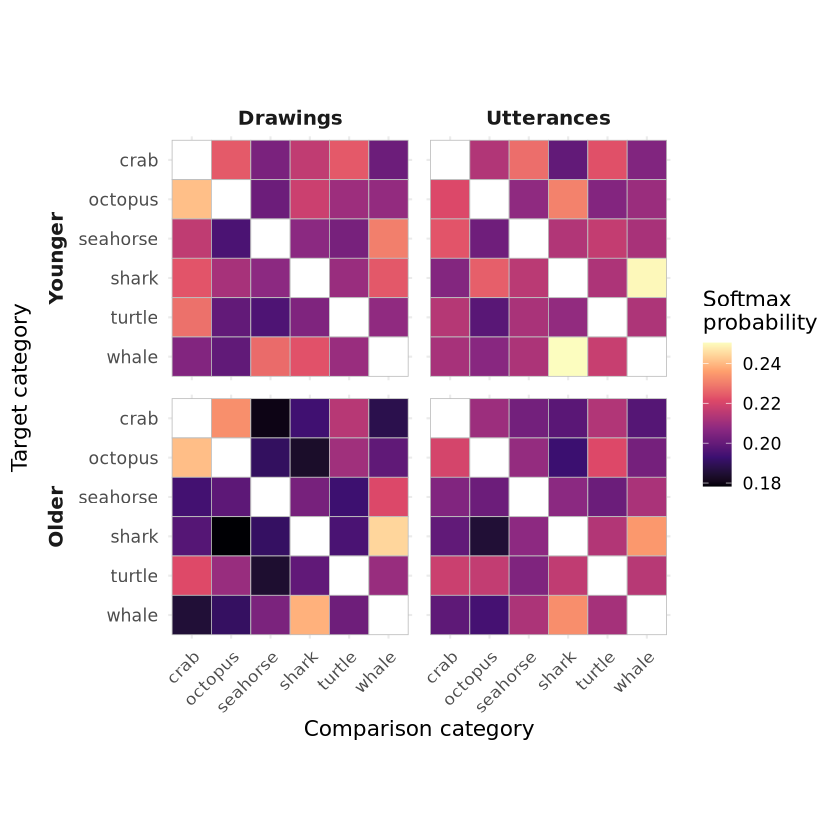

In [14]:
#Fig 5
fill_lim <- range(rdm_plot_df$value, na.rm = TRUE)

# Shorten labels for cleaner strip text
rdm_plot_df_strip <- rdm_plot_df %>%
  mutate(age_group = recode(as.character(age_group),
                            "Younger children" = "Younger",
                            "Older children"   = "Older") %>%
           factor(levels = c("Younger", "Older")))

pw_full <- ggplot(rdm_plot_df_strip, aes(x = col_category, y = row_category, fill = value)) +
  geom_tile(color = "grey") +
  coord_equal() +
  facet_grid(age_group ~ modality, switch = "y") +
  scale_fill_viridis_c(option = "magma", limits = fill_lim, na.value = "white", name = "Softmax\nprobability") +
  labs(x = "Comparison category", y = "Target category") +
  theme_minimal(base_size = 13) +
  theme(
    axis.text.x       = element_text(angle = 45, hjust = 1),
    strip.text.x      = element_text(face = "bold", size = 12),
    strip.text.y.left = element_text(angle = 90, face = "bold", size = 12),
    strip.placement   = "outside",
    panel.spacing     = unit(0.6, "lines"),
    legend.position   = "right"
  )

pw_full
ggsave("../figures/combined_rdm_toself.png", pw_full, width = 8, height = 7, dpi = 300)

In [ ]:
#Correlate lower triangles for younger vs older children
# Younger
younger_test <- cor.test(
  younger_draw_rdm[lower.tri(younger_draw_rdm)],
  younger_utt_rdm[lower.tri(younger_utt_rdm)],
  method = "spearman",
  use = "pairwise.complete.obs"
)

# Older
older_test <- cor.test(
  older_draw_rdm[lower.tri(older_draw_rdm)],
  older_utt_rdm[lower.tri(older_utt_rdm)],
  method = "spearman",
  use = "pairwise.complete.obs"
)

younger_test
older_test



	Spearman's rank correlation rho

data:  younger_draw_rdm[lower.tri(younger_draw_rdm)] and younger_utt_rdm[lower.tri(younger_utt_rdm)]
S = 244, p-value = 0.03102
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.5642857 



	Spearman's rank correlation rho

data:  older_draw_rdm[lower.tri(older_draw_rdm)] and older_utt_rdm[lower.tri(older_utt_rdm)]
S = 56, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
rho 
0.9 


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“The following aesthetics were dropped during statistical transformation: label.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“The following aesthetics were dropped during statistical transformation: label.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“The following aesthetics were dropped during statistical transformation: label.
ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?”
`geom_smoo

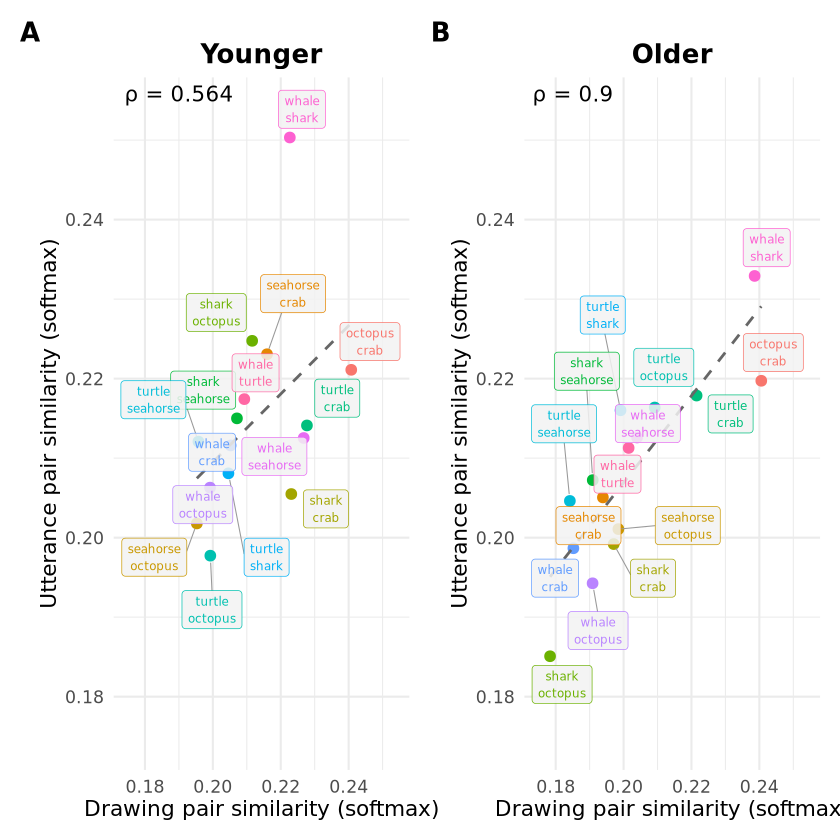

In [ ]:
#Fig 6 

# Cross-modal scatter: each point = one category pair (lower triangle)
# x = drawing probability, y = utterance probability
# This is the data the Spearman rho is derived from
get_lower_tri_df <- function(draw_mat, utt_mat, age_grp) {
  idx <- which(lower.tri(draw_mat), arr.ind = TRUE)
  tibble(
    row_cat   = rownames(draw_mat)[idx[, 1]],
    col_cat   = colnames(draw_mat)[idx[, 2]],
    draw_prob = draw_mat[idx],
    utt_prob  = utt_mat[idx],
    age_group = age_grp
  )
}

cross_df <- bind_rows(
  get_lower_tri_df(younger_draw_rdm, younger_utt_rdm, "Younger children"),
  get_lower_tri_df(older_draw_rdm,   older_utt_rdm,   "Older children")
) %>%
  mutate(
    age_group = factor(age_group, levels = c("Younger children", "Older children")),
    pair      = paste0(row_cat, "\n", col_cat)
  )

# Shared axis limits across both panels
axis_lim <- range(c(cross_df$draw_prob, cross_df$utt_prob), na.rm = TRUE)
axis_pad <- diff(axis_lim) * 0.05
axis_lim <- axis_lim + c(-axis_pad, axis_pad)

make_cross_panel <- function(age_grp, rho_val, display_name) {
  cross_df %>%
    filter(age_group == age_grp) %>%
    ggplot(aes(x = draw_prob, y = utt_prob, color = pair, label = pair)) +
    geom_point(size = 2.5, show.legend = FALSE) +
    geom_smooth(method = "lm", se = FALSE, color = "gray40",
                linetype = "dashed", linewidth = 0.8) +
    geom_label_repel(size = 2.5, max.overlaps = Inf,
                     box.padding = 0.3, point.padding = 0.2,
                     fill = alpha("grey95", 0.85),
                     label.size = 0.2,
                     segment.color = "grey60", segment.size = 0.3,
                     show.legend = FALSE) +
    annotate("text",
             x = -Inf, y = Inf,
             label = paste0("ρ = ", round(rho_val, 3)),
             hjust = -0.1, vjust = 1.5, size = 4.5) +
    scale_x_continuous(limits = axis_lim) +
    scale_y_continuous(limits = axis_lim) +
    labs(
      title = display_name,
      x     = "Drawing pair similarity (softmax)",
      y     = "Utterance pair similarity (softmax)"
    ) +
    theme_minimal(base_size = 13) +
    theme(plot.title = element_text(hjust = 0.5, face = "bold"))
}

pw_cross <- (
  make_cross_panel("Younger children", younger_cor, "Younger") +
  make_cross_panel("Older children",   older_cor,   "Older")
) +
  plot_annotation(tag_levels = "A") &
  theme(plot.tag = element_text(face = "bold"))

pw_cross
ggsave("../figures/cross_modal_rdm_scatter.png", pw_cross, width = 10, height = 5, dpi = 300)